---
title: "Your first PyCPT case"
subtitle: "Folders, the forecast question and the two settings dictionaries"
description: "Set up a PyCPT case for OND 2023 rainfall over Indonesia: version check, data catalog, download_args, cpt_args, setup and plot_domains."
execute:
  enabled: false
---

This chapter starts the PyCPT workflow that the rest of *Learn PyCPT* builds on.
By the end you will have a case folder, a complete description of the forecast
you want to calibrate, and a map of the two domains. Nothing is downloaded from
the IRI Data Library yet, so no account or key is needed.

**The running example:** CFSv2 rainfall forecasts initialized on 1 September 2023
for October to December (OND) 2023 over Indonesia, trained on the 1991-2020
target seasons. It is the same forecast as the
[Fit & diagnose](../chapters/fit-diagnose-2023.qmd) case study, so later chapters
can check PyCPT's high-level workflow against those saved results.

The steps follow IRI's [operational seasonal template](https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb), the
maintained starting point for PyCPT 2.10. Where this page explains behaviour
that the template leaves implicit, the explanation comes from the installed
PyCPT 2.10.4 source.

::: {.callout-note title="What you need to run this page"}
Reading it needs only a browser. Running it needs the full PyCPT environment in
[Setup & downloads](../guides/reproduce.qmd) and this tutorial's repository, which
holds the small figure helper used for the map. The map in step 7 fetches Natural
Earth coastlines the first time it runs, so that cell needs internet access once.
:::

## 1. Check the PyCPT version

PyCPT is several Python packages. `pycpt` holds the high-level workflow used in
these chapters; `cptdl` holds the data catalog and download code. The template
refuses to run below PyCPT 2.10.0. A minimum version is a useful guard, but it
does not prove that every dataset and argument behaves as it did when a page was
written, so we also print the version this page was executed with.

In [1]:
from pathlib import Path
import datetime as dt
import sys
import textwrap

import matplotlib.pyplot as plt
import packaging.version
import pandas as pd
import pycpt
import cptdl as dl

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
sys.path.insert(0, str(repo))
from pycpt_tutorial import figures
figures.use_style()

print(f"Installed PyCPT: {pycpt.__version__}")
print("This page was executed with the pinned PyCPT 2.10.4 environment.")
if packaging.version.parse(pycpt.__version__) < packaging.version.parse("2.10.0"):
    raise RuntimeError("These chapters need PyCPT 2.10.0 or newer. See Setup & downloads.")

Installed PyCPT: 2.10.4
This page was executed with the pinned PyCPT 2.10.4 environment.


## 2. Choose the model and the observations

The catalog is three dictionaries in `cptdl`: `hindcasts`, `forecasts` and
`observations`. Each maps a dataset name to an IRI Data Library URL template.
The template notebook's comment suggests `dl.models.keys()`; in this version that
attribute does not exist, so list `dl.hindcasts` instead.

In [2]:
rain_models = sorted(name for name in dl.hindcasts if name.endswith(".PRCP"))
rain_obs = [name for name in dl.observations if name.endswith(".PRCP")]

print(f"{len(dl.hindcasts)} hindcast entries, {len(rain_models)} of them rainfall (.PRCP):")
print(textwrap.fill(", ".join(rain_models), width=88))
print()
print(f"{len(rain_obs)} rainfall observation entries:")
print(textwrap.fill(", ".join(rain_obs), width=88))
print()
print("Rainfall names marked as deprecated, with their replacements:")
for old, (new, _doc) in dl.catalog.deprecations.items():
    if old.endswith(".PRCP"):
        print(f"  {old} -> {new}")

184 hindcast entries, 28 of them rainfall (.PRCP):
CCSM4.PRCP, CESM1.PRCP, CFSv2.PRCP, CPS2.PRCP, CanCM3.PRCP, CanCM4.PRCP, CanCM4i.PRCP,
CanSIPSIC3.PRCP, CanSIPSIC4.PRCP, CanSIPSv2.PRCP, FLORA06.PRCP, FLORB01.PRCP,
GCFS2p0.PRCP, GCFS2p1.PRCP, GEM5NEMO.PRCP, GEOSS2S.PRCP, GLOSEA5.PRCP, GLOSEA6.PRCP,
METEOFRANCE7.PRCP, METEOFRANCE8.PRCP, METEOFRANCE9.PRCP, SEAS5.PRCP, SEAS51.PRCP,
SEAS51b.PRCP, SEAS51c.PRCP, SPEAR.PRCP, SPSv3p0.PRCP, SPSv3p5.PRCP

11 rainfall observation entries:
ENACTS-BANGLADESH.PRCP, ENACTS-COLOMBIA.PRCP, ENACTS-GAMBIA.PRCP, ENACTS-GUATEMALA.PRCP,
ENACTS-ICPAC.PRCP, ENACTS-VIETNAM.PRCP, CHILESTATIONS.PRCP, UCSB.PRCP, UCSB0p05.PRCP,
CPCCMAPURD.PRCP, TRMM.PRCP

Rainfall names marked as deprecated, with their replacements:
  SEAS51.PRCP -> SEAS51c.PRCP
  SEAS51b.PRCP -> SEAS51c.PRCP


A name in the catalog says what PyCPT *can* request. It does not say that the
model has hindcasts for your initialization month and training years; the next
chapter checks that after downloading.

We pick one model, one observation dataset and the calibration method. `MOS`
(model output statistics) is `"CCA"` or `"PCR"` in the template. Setting
`local_predictand_file` to `None` means the observations come from the catalog;
chapter 3 replaces them with a local CHIRPS3 file.

In [3]:
MOS = "CCA"
predictor_names = ["CFSv2.PRCP"]
predictand_name = "UCSB.PRCP"
local_predictand_file = None

## 3. Describe the forecast: `download_args`

`download_args` defines *which* data to fetch: the initialization date, the
target season, the training years and two bounding boxes.

- `fdate`: the initialization date. Its year is used only for the forecast
  file; for hindcasts only the month matters.
- `target`: the season as `"Mmm-Mmm"`, here `"Oct-Dec"`.
- `target_first_year`, `target_final_year`: the training seasons, labelled by the
  year of the season's *midpoint*. December-February 1999-2000 is the 2000 season.
- `predictor_extent`: the model domain, 85°E-155°E and 20°S-20°N. It covers a
  larger area than the observation box.
- `predictand_extent`: the observation domain, a box around Indonesia.

Both boxes match the Fit & diagnose case. They are a controlled choice, not a
recommendation for the best predictor domain.

In [4]:
download_args = {
    "fdate": dt.datetime(2023, 9, 1),
    "target": "Oct-Dec",
    "target_first_year": 1991,
    "target_final_year": 2020,
    "predictor_extent": {"west": 85, "east": 155, "south": -20, "north": 20},
    "predictand_extent": {"west": 94, "east": 142, "south": -12, "north": 7},
}

## 4. See what PyCPT will actually request

Before downloading, it helps to see how PyCPT turns these settings into a
request. Two conversions happen. The target season becomes a **lead range** in
months after initialization. The training years, given as *target* years, become
*initialization* years, which differ when the forecast is issued in the calendar
year before the season's midpoint.

The table applies PyCPT's own helpers to our case and to two cross-year seasons
for contrast.

In [5]:
rows = []
for issue_month, target in [(9, "Oct-Dec"), (11, "Dec-Feb"), (12, "Jan-Mar")]:
    lead_low, lead_high = dl.leads_from_target(dt.datetime(2023, issue_month, 1), target)
    rows.append({
        "issue month": dt.date(2023, issue_month, 1).strftime("%b"),
        "target": target,
        "season midpoint (month number)": pycpt.target_midpoint(target),
        "lead_low": lead_low,
        "lead_high": lead_high,
        "initialization year = target year +": pycpt.issue_year_delta(issue_month, target),
    })
pd.DataFrame(rows)

,issue month,target,season midpoint (month number),lead_low,lead_high,initialization year = target year +
0,Sep,Oct-Dec,11.5,1.5,3.5,0
1,Nov,Dec-Feb,1.5,1.5,3.5,-1
2,Dec,Jan-Mar,2.5,1.5,3.5,-1


For OND from a September start the leads are 1.5 to 3.5 months and the years do
not shift, so training seasons 1991-2020 use September initializations 1991-2020.
A December-February forecast issued in November would use initializations from the
previous calendar year.

PyCPT does this conversion in an internal function, `_preprocess_download_args`.
We call it here only to show the values it will use; do not build your own code on
an underscore-prefixed function. The resolved values fill the URL template, which
is the exact recipe sent to the Data Library.

In [6]:
from pycpt import notebook as pycpt_notebook

resolved = pycpt_notebook._preprocess_download_args(download_args)
for key in ["lead_low", "lead_high", "first_year", "final_year", "filetype"]:
    print(f"{key:>10}: {resolved[key]}")


def show_url(label, template):
    url = dl.evaluate_url(template, **resolved)
    print(f"\n{label}:")
    print(textwrap.fill(url, width=88, break_on_hyphens=False))


show_url("CFSv2 hindcasts", dl.hindcasts["CFSv2.PRCP"])
show_url("CFSv2 forecast", dl.forecasts["CFSv2.PRCP"])
show_url("UCSB observations", dl.observations["UCSB.PRCP"])

  lead_low: 1.5
 lead_high: 3.5
first_year: 1991
final_year: 2020
  filetype: cptv10.tsv

CFSv2 hindcasts:
https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMP
LES_FULL/.prec/S/%280000%201%20Sep%201991-2020%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//k
eepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/set
missing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv

CFSv2 forecast:
https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMP
LES_FULL/.prec/S/%280000%201%20Sep%202023%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//keepgr
ids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissi
ng_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv

UCSB observations:
https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.daily-improved/.global/.0p2
5/.prcp/92/mul/T/(1%20Jan%201991)/(31%20Dec%202020)/RANGE/T/%28Oct-Dec%201991-2020%29/se
asonalAverage/Y/%28-12%29/%287%29/RANGEEDGES/X/%2894%

Reading the URLs is worth a minute. Each is a chain of Data Library operations,
applied left to right:

- **CFSv2:** select September starts (`S`) and leads 1.5 to 3.5 (`L`), average
  over those leads, cut the box, average over ensemble members (`[M]average`),
  then multiply by 92, the number of days in OND. The result is an ensemble-mean
  seasonal total.
- **The forecast** comes from the same Data Library collection as the hindcasts;
  only the start date changes, to September 2023.
- **Observations:** CHIRPS v2.0 daily data on a 0.25° grid, multiplied by 92 and
  averaged over each OND season, which again gives a seasonal total.

When results look surprising later, these URLs are the first place to check what
was actually requested.

## 5. Fix the model settings: `cpt_args`

`cpt_args` defines *how* CPT fits the model. The template allows CPT to choose
the number of modes within ranges such as `(1, 8)`. Here every range has equal
ends, so the mode counts are fixed at the values used in Fit & diagnose. That
keeps the comparison in chapter 3 exact. Fixed counts are a teaching control,
not a tuned configuration for Indonesia.

In [7]:
cpt_args = {
    "transform_predictand": None,   # disabled upstream until fixed
    "tailoring": None,
    "cca_modes": (2, 2),            # (minimum, maximum) CCA modes
    "x_eof_modes": (3, 3),          # predictor EOF modes
    "y_eof_modes": (3, 3),          # predictand EOF modes
    "validation": "crossvalidation",
    "drymask_threshold": None,
    "skillmask_threshold": None,
    "crossvalidation_window": 5,
    "synchronous_predictors": True,
}
pd.Series(cpt_args, name="value").to_frame()

,value
transform_predictand,None
tailoring,None
cca_modes,"(2, 2)"
x_eof_modes,"(3, 3)"
y_eof_modes,"(3, 3)"
validation,crossvalidation
drymask_threshold,None
skillmask_threshold,None
crossvalidation_window,5
synchronous_predictors,True


Three settings deserve attention now. `crossvalidation_window=5` leaves out each
training season together with its two neighbours on either side, wrapping at the
ends of the period, so a cross-validated hindcast is not fitted on the year it
predicts. The [Fit & diagnose notebook](../notebooks/fit-diagnose-2023.ipynb)
documents this window for the same CPT 17.8.3 engine.
`transform_predictand` stays `None` because the template marks transformations as
disabled until upstream bugs are fixed. With the masks set to `None`, every
location is fitted and kept.

## 6. Create the case folder: `setup`

`setup` creates a folder for this domain with `data`, `figures` and `output`
inside it, and returns its path. The template passes the **predictor** extent.

In [8]:
case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = pycpt.setup(case_dir, download_args["predictor_extent"])

print()
print("Domain folder name:", domain_dir.name)
print("Contents:", sorted(p.name for p in domain_dir.iterdir()))

Input data will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/output

Domain folder name: 85W-155E_to_-20S-20N
Contents: ['data', 'figures', 'output']


Two details in that folder are easy to miss.

**The folder name uses signed numbers with fixed letters.** PyCPT writes
`{west}W-{east}E_to_{south}S-{north}N`. Our name, `85W-155E_to_-20S-20N`, therefore
means 85°E to 155°E and 20°S to 20°N. Read the numbers, not the letters.

**Downloaded files are named by dataset only.** The next cell lists the names
PyCPT will use for our case.

In [9]:
year = download_args["fdate"].year
planned = [f"{name}.nc" for name in predictor_names]
planned += [f"{name}_f{year}.nc" for name in predictor_names]
planned += [f"{predictand_name}.nc"]
for name in planned:
    print(domain_dir / "data" / name)

~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data/CFSv2.PRCP.nc
~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data/CFSv2.PRCP_f2023.nc
~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data/UCSB.PRCP.nc


None of these names contains the target season, initialization month, training
years or predictand domain. In PyCPT 2.10.4 the download helper reuses any
existing file with that name unless `force_download=True`. If you change the
season or years but keep the same case folder and set `force_download=False`,
PyCPT will quietly reuse data for the old question.

The safe habit: **one case folder per forecast question**, as the name
`indonesia-ond-2023-sep-init` does here, and `force_download=True` whenever you
change `download_args` in an existing folder.

## 7. Map the domains

A quick map catches swapped signs or a box in the wrong hemisphere before any
download. PyCPT's own check is

```python
pycpt.plot_domains(download_args["predictor_extent"], download_args["predictand_extent"])
```

which draws the two boxes in two small separate panels. This tutorial draws both
boxes on one map with its figure helper, so you can see how they sit together.

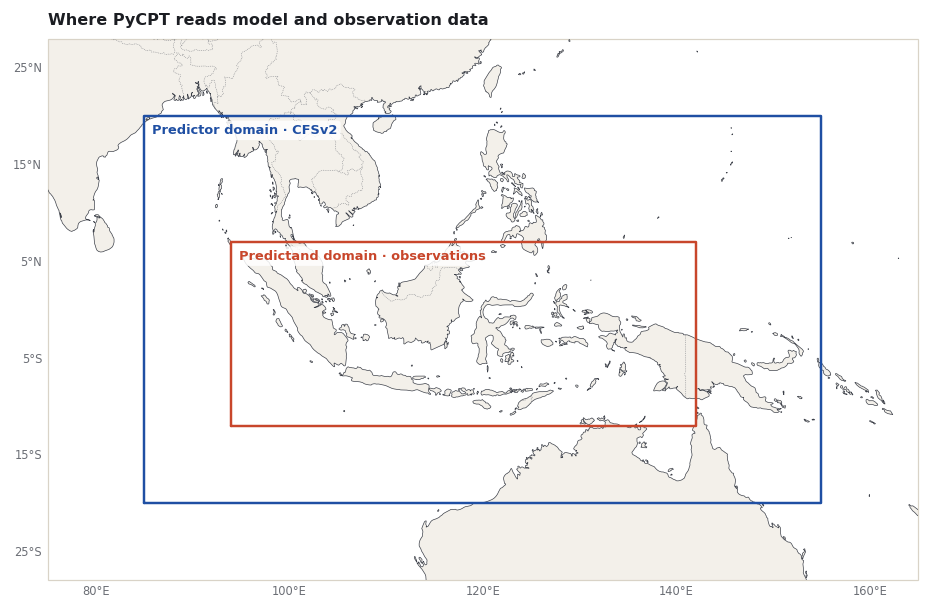

In [10]:
fig = plt.figure(figsize=(9, 5.4), layout="constrained")
ax = figures.map_axes(fig, 111, (75, 165, -28, 28), land=True)
figures.box(ax, figures.extent_of(download_args["predictor_extent"]), figures.ACCENT, "Predictor domain · CFSv2")
figures.box(ax, figures.extent_of(download_args["predictand_extent"]), figures.MARK, "Predictand domain · observations")
ax.set_title("Where PyCPT reads model and observation data")
plt.show()

The blue box is the predictor (model) domain; the red box is the predictand
(observation) domain, where the calibrated forecasts are produced and verified.

## What you have now

- A version check and the catalog names for one model and one observation dataset.
- `download_args`: the forecast question, with its leads and initialization years
  checked before any download.
- `cpt_args`: fixed, documented fitting choices.
- A case folder, and two habits that prevent silent mistakes: read the folder name's
  numbers, and keep one case folder per forecast question.

The next chapter downloads the hindcasts, forecast and observations into this
folder and checks which years actually arrived.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
3. IRI. *PyCPT 2.10.4 source: `cptdl`* (data catalog, `leads_from_target`, `evaluate_url`, `download`, `simple_download`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/tree/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptdl>
4. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
5. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
6. Kirtman, B., Min, D., Infanti, J., et al. (2014). The North American Multimodel Ensemble: Phase-1 seasonal-to-interannual prediction; Phase-2 toward developing intraseasonal prediction. *Bulletin of the American Meteorological Society*, 95(4), 585-601. <https://doi.org/10.1175/BAMS-D-12-00050.1>
7. IRI Data Library. *UCSB CHIRPS version 2.0*. <https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
8. Funk, C., Peterson, P., Landsfeld, M., et al. (2015). The climate hazards infrared precipitation with stations: a new environmental record for monitoring extremes. *Scientific Data*, 2, 150066. <https://doi.org/10.1038/sdata.2015.66>
9. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
10. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>